# 3. Robustness and controls
1. **Noise × temptation sweep:** does optimism evolve across levels of action noise and temptation to defect?
2. **Controls:** neutral drift (random fitness); individual vs multi-agent learning at matched farsightedness.
3. **Starting values:** is the result sensitive to agents' initial expectations?
4. **Original vs corrected settings:** reproduces the methodological issue described in the README.
5. **Payoff scaling and choice noise:** is the temptation effect driven by payoff gaps interacting with a fixed β?
6. **Learning rates and population distributions:** α⁺ and α⁻ separately; are evolved populations unimodal?

The whole notebook takes about an hour (20 runs per condition).

In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Model code
This cell contains the full contents of `evolution.py`, so the notebook runs on its own (e.g. in Google Colab) without uploading any other files.

In [ ]:
"""
evolution.py -- Evolving learning biases (alpha+, alpha-) in populations
=========================================================================
Project: Does evolution favour optimistic learners in social dilemmas?

Each generation:
  1. Every agent lives one "lifetime" in an environment and learns with its
     own (alpha_pos, alpha_neg).  Fitness = mean reward obtained.
  2. Parents are sampled with probability increasing in fitness
     (rank-based selection, Wright-Fisher style).
  3. Offspring inherit their parent's (alpha_pos, alpha_neg) + Gaussian mutation.

Environments (same evolutionary loop):
  * bandit_lifetime            individual learning, myopic (gamma = 0)
                               -> conceptual replication of Hoxha, Sperber &
                                  Palminteri (2025, PNAS)
  * bandit_lifetime_farsighted individual learning, farsighted (gamma > 0) -- control
  * ipd_lifetime               multi-agent learning: agents learn against each other
                               in the Iterated Prisoner's Dilemma -- extension
  * random_lifetime            fitness is pure noise -- neutral-drift control

Scaling conventions (applied in every environment, so conditions are comparable):
  * Payoffs lie in [0, 1].
  * Starting values  Q0 = 0.5 / (1 - gamma)   (neutral given the discount factor)
  * Softmax is applied to (1 - gamma) * Q      (same choice noise for any gamma)
Both can be overridden (q_init=..., rescale=False) to reproduce the original,
flawed settings discussed in the README.

Everything is vectorised over the population with NumPy.
"""

import numpy as np


def softmax_choice(Q, beta, rng):
    """Vectorised softmax over the last axis. Q: (n, 2). Returns actions (n,)."""
    z = beta * (Q - Q.max(axis=1, keepdims=True))
    p1 = np.exp(z[:, 1]) / np.exp(z).sum(axis=1)
    return (rng.random(len(Q)) < p1).astype(int)


def asym_update(q, delta, a_pos, a_neg):
    """Asymmetric learning-rate update, vectorised."""
    lr = np.where(delta > 0, a_pos, a_neg)
    return q + lr * delta


def neutral_q(gamma):
    """Neutral starting value: midpoint payoff (0.5) summed over the discounted future."""
    return 0.5 / (1 - gamma)


# ------------------------------------------------------------------
# Lifetimes
# ------------------------------------------------------------------
def bandit_lifetime_farsighted(a_pos, a_neg, rng, probs=(0.25, 0.75), n_trials=100,
                               beta=10.0, gamma=0.9, q_init=None, rescale=True):
    """Each agent independently learns a 2-armed Bernoulli bandit.
    Arm positions are randomised per agent. Returns fitness (n,)."""
    n = len(a_pos)
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    best = rng.integers(0, 2, n)                       # which arm is better
    p = np.where(best[:, None] == np.arange(2), probs[1], probs[0])  # (n, 2)
    Q = np.full((n, 2), float(q_init))
    total = np.zeros(n)
    idx = np.arange(n)
    for _ in range(n_trials):
        a = softmax_choice(Q * scale, beta, rng)
        r = (rng.random(n) < p[idx, a]).astype(float)
        delta = r + gamma * Q.max(axis=1) - Q[idx, a]
        Q[idx, a] = asym_update(Q[idx, a], delta, a_pos, a_neg)
        total += r
    return total / n_trials


def bandit_lifetime(a_pos, a_neg, rng, **kw):
    """Myopic bandit (gamma = 0): the standard individual-learning task."""
    kw.setdefault("gamma", 0.0)
    return bandit_lifetime_farsighted(a_pos, a_neg, rng, **kw)


def make_pd(temptation=5.0, reward=3.0, punishment=1.0, sucker=0.0, payoff_scale=None):
    """PD payoff matrix PD[my_action, their_action].
    By default divided by T (min-max scaling to [0, 1], since S = 0). With a fixed
    payoff_scale (e.g. 5.5 = the largest T used), the gaps between outcomes no
    longer change with T, so choice noise under a fixed beta is comparable across T."""
    scale = temptation if payoff_scale is None else payoff_scale
    return np.array([[reward, sucker],
                     [temptation, punishment]], dtype=float) / scale


def ipd_lifetime(a_pos, a_neg, rng, n_rounds=100, n_partners=4, noise=0.05,
                 beta=10.0, gamma=0.9, q_init=None, rescale=True,
                 temptation=5.0, payoff_scale=None, log=None):
    """Agents are randomly paired and play the iterated PD, learning online
    (state = partner's last move; 2 = first round). Repeated with
    n_partners random pairings; Q-values are reset for each new partner and the
    first round with each partner uses state 2 ("no history").
    Returns fitness (n,) = mean payoff per round.
    If log is a list, appends (realised cooperation, intended cooperation), where
    intended = the agent's choice before the trembling-hand flip."""
    n = len(a_pos)
    assert n % 2 == 0
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    pd = make_pd(temptation, payoff_scale=payoff_scale)
    fitness = np.zeros(n)
    coop = coop_int = 0.0
    for _ in range(n_partners):
        perm = rng.permutation(n)
        i, j = perm[: n // 2], perm[n // 2:]            # pair i[k] with j[k]
        Q = np.full((n, 3, 2), float(q_init))           # fresh learning per partner
        s = np.full(n, 2)
        idx = np.arange(n)
        for _ in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop_int += (a == 0).mean()
            flip = rng.random(n) < noise                # trembling hand
            a = np.where(flip, 1 - a, a)
            partner_a = np.empty(n, dtype=int)
            partner_a[i], partner_a[j] = a[j], a[i]
            r = pd[a, partner_a]
            coop += (a == 0).mean()
            s_next = partner_a                          # observe partner's move
            target = r + gamma * Q[idx, s_next].max(axis=1)
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, a_pos, a_neg)
            s = s_next
            fitness += r
    if log is not None:                                 # optional: record cooperation
        log.append((coop / (n_rounds * n_partners), coop_int / (n_rounds * n_partners)))
    return fitness / (n_rounds * n_partners)


def random_lifetime(a_pos, a_neg, rng, **_):
    """Control: fitness is pure noise, unrelated to (alpha+, alpha-).
    Shows what mutation + clipping + drift alone do to the optimism index."""
    return rng.random(len(a_pos))


# ------------------------------------------------------------------
# Evolutionary loop
# ------------------------------------------------------------------
def evolve(lifetime, n_agents=100, n_generations=150, mut_sd=0.03,
           selection=2.0, init="uniform", seed=0, **env_kwargs):
    """Run evolution. Returns dict of per-generation traces."""
    rng = np.random.default_rng(seed)
    if init == "uniform":
        a_pos = rng.uniform(0.05, 0.95, n_agents)
        a_neg = rng.uniform(0.05, 0.95, n_agents)
    else:                                               # start unbiased
        a_pos = np.full(n_agents, init)
        a_neg = np.full(n_agents, init)

    trace = {k: [] for k in ("a_pos", "a_neg", "bias", "fitness", "coop", "coop_intended")}
    for g in range(n_generations):
        log = []
        if lifetime is ipd_lifetime:
            fit = lifetime(a_pos, a_neg, rng, log=log, **env_kwargs)
        else:
            fit = lifetime(a_pos, a_neg, rng, **env_kwargs)
        trace["coop"].append(log[0][0] if log else np.nan)
        trace["coop_intended"].append(log[0][1] if log else np.nan)
        bias = (a_pos - a_neg) / (a_pos + a_neg)
        trace["a_pos"].append(a_pos.mean())
        trace["a_neg"].append(a_neg.mean())
        trace["bias"].append(bias.mean())
        trace["fitness"].append(fit.mean())

        # rank-based selection: P(parent) ~ exp(selection * rank / n)
        ranks = fit.argsort().argsort() / (n_agents - 1)
        w = np.exp(selection * ranks); w /= w.sum()
        parents = rng.choice(n_agents, size=n_agents, p=w)
        a_pos = np.clip(a_pos[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)
        a_neg = np.clip(a_neg[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)

    out = {k: np.array(v) for k, v in trace.items()}
    out["final_a_pos"], out["final_a_neg"] = a_pos, a_neg    # final population (for distributions)
    return out


def summarise(runs, last=30):
    """Mean and SE (across seeds) of the optimism index over the last generations,
    plus mean cooperation."""
    b = np.array([r["bias"][-last:].mean() for r in runs])
    def coop(key):
        if np.all(np.isnan(runs[0][key])):
            return np.nan
        return np.mean([r[key][-last:].mean() for r in runs])
    return dict(optimism=b.mean(), se=b.std(ddof=1) / np.sqrt(len(b)),
                cooperation=coop("coop"), cooperation_intended=coop("coop_intended"),
                a_pos=np.mean([r["a_pos"][-last:].mean() for r in runs]),
                a_neg=np.mean([r["a_neg"][-last:].mean() for r in runs]))


In [ ]:
N_SEEDS, N_GEN, LAST = 20, 150, 30
def run(fn, **kw):
    return summarise([evolve(fn, n_generations=N_GEN, seed=s, **kw) for s in range(N_SEEDS)], LAST)

## 1. Noise × temptation sweep (~25 min)
Cooperation is reported both as *intended* (the agent's choice) and *realised* (after the trembling-hand flip);
at high noise the realised measure is pulled toward 50%.

In [ ]:
NOISES = [0.0, 0.02, 0.05, 0.10, 0.20]
TEMPTATIONS = [3.5, 4.0, 5.0, 5.5]        # T must satisfy R = 3 < T < 6 (= 2R - S)
rows, t0 = [], time.time()
for T in TEMPTATIONS:
    for nz in NOISES:
        s = run(ipd_lifetime, noise=nz, temptation=T)
        rows.append(dict(temptation=T, noise=nz, **s))
        print(f"T={T:<4} noise={nz:<5} optimism={s['optimism']:+.2f} (SE {s['se']:.2f})  "
              f"alpha+={s['a_pos']:.2f} alpha-={s['a_neg']:.2f}  "
              f"coop intended={s['cooperation_intended']:.2f} realised={s['cooperation']:.2f}  [{time.time()-t0:.0f}s]")
sweep = pd.DataFrame(rows); sweep.to_csv("results/sweep.csv", index=False)

T=3.5  noise=0.0   optimism=+0.06 (SE 0.04)  alpha+=0.77 alpha-=0.72  coop intended=0.44 realised=0.44  [142s]
T=3.5  noise=0.02  optimism=+0.02 (SE 0.05)  alpha+=0.71 alpha-=0.72  coop intended=0.44 realised=0.44  [280s]
T=3.5  noise=0.05  optimism=-0.03 (SE 0.05)  alpha+=0.68 alpha-=0.72  coop intended=0.44 realised=0.45  [417s]
T=3.5  noise=0.1   optimism=-0.18 (SE 0.05)  alpha+=0.57 alpha-=0.76  coop intended=0.44 realised=0.45  [553s]
T=3.5  noise=0.2   optimism=-0.26 (SE 0.06)  alpha+=0.46 alpha-=0.73  coop intended=0.44 realised=0.47  [690s]
T=4.0  noise=0.0   optimism=+0.57 (SE 0.06)  alpha+=0.81 alpha-=0.27  coop intended=0.43 realised=0.43  [826s]
T=4.0  noise=0.02  optimism=+0.58 (SE 0.04)  alpha+=0.81 alpha-=0.24  coop intended=0.43 realised=0.43  [963s]
T=4.0  noise=0.05  optimism=+0.53 (SE 0.05)  alpha+=0.77 alpha-=0.27  coop intended=0.43 realised=0.44  [1098s]
T=4.0  noise=0.1   optimism=+0.32 (SE 0.06)  alpha+=0.77 alpha-=0.48  coop intended=0.44 realised=0.45  [1237s]

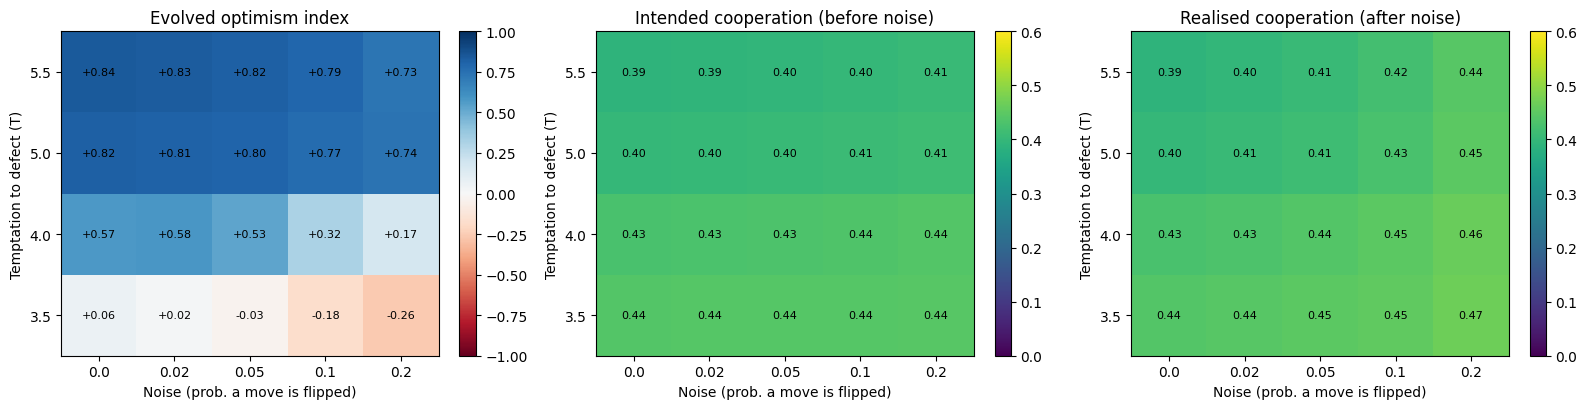

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col, title, cmap, vlim in [
    (axes[0], "optimism",             "Evolved optimism index",              "RdBu",    (-1, 1)),
    (axes[1], "cooperation_intended", "Intended cooperation (before noise)", "viridis", (0, 0.6)),
    (axes[2], "cooperation",          "Realised cooperation (after noise)",  "viridis", (0, 0.6))]:
    grid = sweep.pivot(index="temptation", columns="noise", values=col)
    im = ax.imshow(grid.values, cmap=cmap, vmin=vlim[0], vmax=vlim[1], origin="lower", aspect="auto")
    ax.set_xticks(range(len(NOISES)), [str(n) for n in NOISES])
    ax.set_yticks(range(len(TEMPTATIONS)), [str(t) for t in TEMPTATIONS])
    ax.set(xlabel="Noise (prob. a move is flipped)", ylabel="Temptation to defect (T)", title=title)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:+.2f}" if col == "optimism" else f"{v:.2f}", ha="center", va="center",
                    fontsize=8, color="white" if col != "optimism" and v < 0.3 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig("figures/03_sweep.png", dpi=150); plt.show()

## 2. Controls (noise = 0.05, T = 5)
The key comparison is **farsighted bandit vs farsighted IPD**: both use γ = 0.9, so the only difference is
whether the environment is a fixed slot machine or another learning agent. With γ = 0 in the IPD, defection
beats cooperation whatever the partner does, so the learning bias should barely change behaviour.

In [ ]:
CONTROLS = [
    ("Drift only\n(random fitness)", random_lifetime,            {}),
    ("Bandit\nmyopic",               bandit_lifetime,            {}),
    ("Bandit\nfarsighted",           bandit_lifetime_farsighted, {}),
    ("IPD\nmyopic",                  ipd_lifetime,               dict(noise=0.05, gamma=0.0)),
    ("IPD\nfarsighted",              ipd_lifetime,               dict(noise=0.05, gamma=0.9)),
]
control = {}
for label, fn, kw in CONTROLS:
    control[label] = c = run(fn, **kw)
    print(f"{label.replace(chr(10), ' '):<28} optimism={c['optimism']:+.2f} (SE {c['se']:.2f})  "
          f"alpha+={c['a_pos']:.2f} alpha-={c['a_neg']:.2f}")

Drift only (random fitness)  optimism=+0.09 (SE 0.09)  alpha+=0.53 alpha-=0.45
Bandit myopic                optimism=+0.56 (SE 0.02)  alpha+=0.60 alpha-=0.17
Bandit farsighted            optimism=+0.27 (SE 0.06)  alpha+=0.68 alpha-=0.51
IPD myopic                   optimism=+0.16 (SE 0.09)  alpha+=0.76 alpha-=0.68
IPD farsighted               optimism=+0.80 (SE 0.01)  alpha+=0.82 alpha-=0.10


## 3. Sensitivity to starting values
**Farsighted agents (γ = 0.9; neutral start = 5).**

In [ ]:
Q_INITS = [1.0, 2.5, 4.0, 5.5, 7.0, 8.5]
qsens = {"IPD (multi-agent)": [], "Bandit (individual)": []}
for q in Q_INITS:
    qsens["IPD (multi-agent)"].append(run(ipd_lifetime, noise=0.05, q_init=q))
    qsens["Bandit (individual)"].append(run(bandit_lifetime_farsighted, q_init=q))
    print(f"q_init={q}: IPD {qsens['IPD (multi-agent)'][-1]['optimism']:+.2f}, "
          f"bandit {qsens['Bandit (individual)'][-1]['optimism']:+.2f}")

q_init=1.0: IPD +0.71, bandit +0.67
q_init=2.5: IPD +0.75, bandit +0.69
q_init=4.0: IPD +0.80, bandit +0.58
q_init=5.5: IPD +0.80, bandit +0.08
q_init=7.0: IPD +0.82, bandit -0.03
q_init=8.5: IPD +0.79, bandit -0.03


**Myopic bandit (the replication itself, γ = 0; neutral start = 0.5).** If optimism partly compensates
for starting values that are too low, it should shrink when agents start out over-expecting.

In [ ]:
Q_INITS_MYOPIC = [0.0, 0.25, 0.5, 0.75, 1.0]
qsens_myopic = [run(bandit_lifetime, q_init=q) for q in Q_INITS_MYOPIC]
for q, v in zip(Q_INITS_MYOPIC, qsens_myopic):
    print(f"Myopic bandit, q_init={q}: optimism={v['optimism']:+.2f} (SE {v['se']:.2f})")

Myopic bandit, q_init=0.0: optimism=+0.34 (SE 0.03)
Myopic bandit, q_init=0.25: optimism=+0.50 (SE 0.02)
Myopic bandit, q_init=0.5: optimism=+0.56 (SE 0.02)
Myopic bandit, q_init=0.75: optimism=+0.33 (SE 0.02)
Myopic bandit, q_init=1.0: optimism=+0.31 (SE 0.02)


**Low temptation.** The sweep shows a pessimism bias at T = 3.5 with high noise; does it survive different starting values?

In [ ]:
qsens_lowT = {}
for nz in [0.0, 0.2]:
    for q in [2.5, 5.0, 7.5]:
        qsens_lowT[(nz, q)] = s = run(ipd_lifetime, noise=nz, temptation=3.5, q_init=q)
        print(f"T=3.5, noise={nz}, q_init={q}: optimism={s['optimism']:+.2f} (SE {s['se']:.2f})")

T=3.5, noise=0.0, q_init=2.5: optimism=+0.19 (SE 0.03)
T=3.5, noise=0.0, q_init=5.0: optimism=+0.06 (SE 0.04)
T=3.5, noise=0.0, q_init=7.5: optimism=-0.10 (SE 0.04)
T=3.5, noise=0.2, q_init=2.5: optimism=-0.34 (SE 0.07)
T=3.5, noise=0.2, q_init=5.0: optimism=-0.26 (SE 0.06)
T=3.5, noise=0.2, q_init=7.5: optimism=-0.29 (SE 0.05)


## 4. Original vs corrected settings (farsighted IPD, noise = 0.05)
The original version used starting values of 0.5 (far below the true values of ~2–6 when γ = 0.9)
and applied the softmax to unscaled values (so agents chose almost greedily). See the README note.

In [ ]:
SETTINGS = [
    ("Original\n(start 0.5, unscaled)", dict(q_init=0.5, rescale=False)),
    ("Neutral start\nonly",             dict(rescale=False)),
    ("Scaled choice\nonly",             dict(q_init=0.5)),
    ("Corrected\n(both)",               dict()),
]
audit = {}
for label, kw in SETTINGS:
    audit[label] = run(ipd_lifetime, noise=0.05, **kw)
    print(f"{label.replace(chr(10), ' '):<34} optimism={audit[label]['optimism']:+.2f} "
          f"(SE {audit[label]['se']:.2f})")

pd.DataFrame([dict(analysis="control", condition=k.replace(chr(10), " "), **v) for k, v in control.items()] +
             [dict(analysis="q_init", condition=f"{name}, q_init={q}", **v)
              for name, vs in qsens.items() for q, v in zip(Q_INITS, vs)] +
             [dict(analysis="q_init", condition=f"Myopic bandit, q_init={q}", **v)
              for q, v in zip(Q_INITS_MYOPIC, qsens_myopic)] +
             [dict(analysis="q_init", condition=f"IPD T=3.5 noise={nz}, q_init={q}", **v)
              for (nz, q), v in qsens_lowT.items()] +
             [dict(analysis="settings", condition=k.replace(chr(10), " "), **v) for k, v in audit.items()]
            ).to_csv("results/controls.csv", index=False)

Original (start 0.5, unscaled)     optimism=-0.17 (SE 0.03)
Neutral start only                 optimism=+0.79 (SE 0.01)
Scaled choice only                 optimism=+0.67 (SE 0.02)
Corrected (both)                   optimism=+0.80 (SE 0.01)


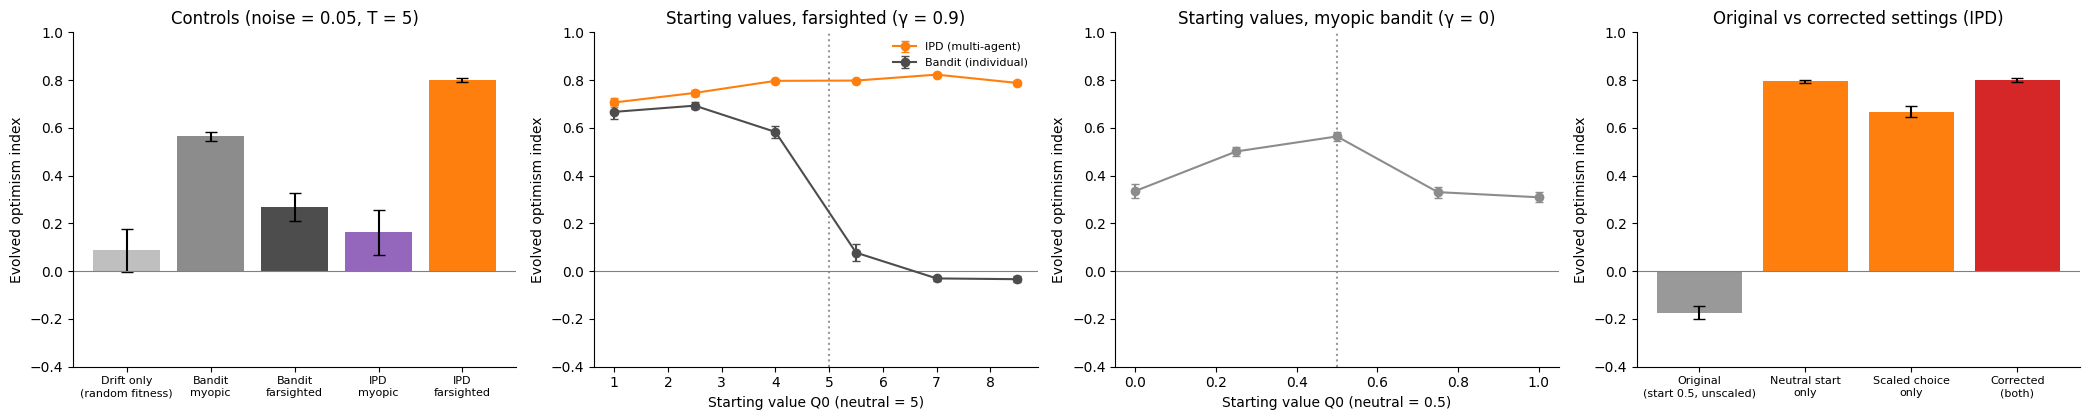

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
def bars(ax, d, colors, title):
    labels = list(d)
    ax.bar(range(len(labels)), [d[k]["optimism"] for k in labels],
           yerr=[d[k]["se"] for k in labels], capsize=4, color=colors)
    ax.axhline(0, c="0.5", lw=0.8)
    ax.set_xticks(range(len(labels)), labels, fontsize=8)
    ax.set(title=title, ylabel="Evolved optimism index", ylim=(-0.4, 1))
bars(axes[0], control, ["0.75", "0.55", "0.3", "tab:purple", "tab:orange"], "Controls (noise = 0.05, T = 5)")
for (name, vs), c in zip(qsens.items(), ["tab:orange", "0.3"]):
    axes[1].errorbar(Q_INITS, [v["optimism"] for v in vs], yerr=[v["se"] for v in vs],
                     marker="o", color=c, label=name, capsize=3)
axes[1].axvline(5, ls=":", c="0.6"); axes[1].axhline(0, c="0.5", lw=0.8)
axes[1].set(title="Starting values, farsighted (γ = 0.9)", xlabel="Starting value Q0 (neutral = 5)",
            ylabel="Evolved optimism index", ylim=(-0.4, 1))
axes[1].legend(frameon=False, fontsize=8)
axes[2].errorbar(Q_INITS_MYOPIC, [v["optimism"] for v in qsens_myopic], yerr=[v["se"] for v in qsens_myopic],
                 marker="o", color="0.55", capsize=3)
axes[2].axvline(0.5, ls=":", c="0.6"); axes[2].axhline(0, c="0.5", lw=0.8)
axes[2].set(title="Starting values, myopic bandit (γ = 0)", xlabel="Starting value Q0 (neutral = 0.5)",
            ylabel="Evolved optimism index", ylim=(-0.4, 1))
bars(axes[3], audit, ["0.6", "tab:orange", "tab:orange", "tab:red"], "Original vs corrected settings (IPD)")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/03_controls.png", dpi=150); plt.show()

## 5. Payoff scaling and choice noise (~15 min)
By default payoffs are divided by T, so the gaps between outcomes (e.g. R − P = 2/T) shrink as T grows. With β
fixed, this changes effective choice noise across T. Here I divide all payoffs by a **fixed** constant (5.5, the
largest T), so the gaps no longer depend on T, and cross T with three values of β. If the temptation effect
survives, it reflects the payoff structure rather than exploration.

fixed scale | T=3.5 noise=0.0 beta=5.0 : optimism=-0.20 (SE 0.04)
fixed scale | T=3.5 noise=0.0 beta=10.0: optimism=-0.25 (SE 0.04)
fixed scale | T=3.5 noise=0.0 beta=20.0: optimism=-0.08 (SE 0.02)
fixed scale | T=3.5 noise=0.2 beta=5.0 : optimism=-0.08 (SE 0.06)
fixed scale | T=3.5 noise=0.2 beta=10.0: optimism=-0.24 (SE 0.05)
fixed scale | T=3.5 noise=0.2 beta=20.0: optimism=-0.39 (SE 0.05)
fixed scale | T=5.0 noise=0.0 beta=5.0 : optimism=+0.67 (SE 0.04)
fixed scale | T=5.0 noise=0.0 beta=10.0: optimism=+0.80 (SE 0.01)
fixed scale | T=5.0 noise=0.0 beta=20.0: optimism=+0.85 (SE 0.00)
fixed scale | T=5.0 noise=0.2 beta=5.0 : optimism=+0.47 (SE 0.06)
fixed scale | T=5.0 noise=0.2 beta=10.0: optimism=+0.69 (SE 0.03)
fixed scale | T=5.0 noise=0.2 beta=20.0: optimism=+0.82 (SE 0.01)


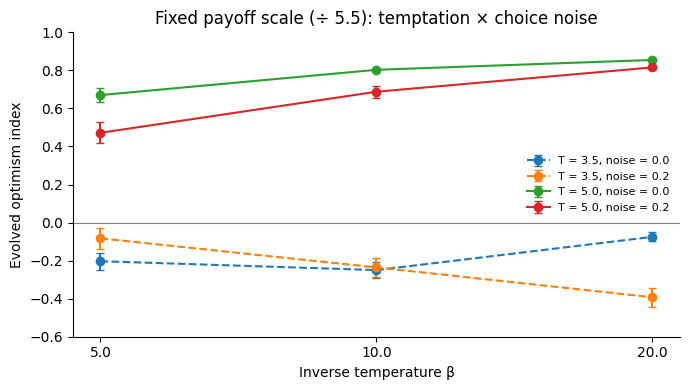

In [ ]:
BETAS = [5.0, 10.0, 20.0]
scaling = []
for T in [3.5, 5.0]:
    for nz in [0.0, 0.2]:
        for b in BETAS:
            s = run(ipd_lifetime, noise=nz, temptation=T, beta=b, payoff_scale=5.5)
            scaling.append(dict(temptation=T, noise=nz, beta=b, **s))
            print(f"fixed scale | T={T} noise={nz} beta={b:<4}: optimism={s['optimism']:+.2f} (SE {s['se']:.2f})")
scaling = pd.DataFrame(scaling); scaling.to_csv("results/payoff_scaling.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for (T, nz), g in scaling.groupby(["temptation", "noise"]):
    ax.errorbar(g.beta, g.optimism, yerr=g.se, marker="o", capsize=3,
                ls="-" if T == 5.0 else "--", label=f"T = {T}, noise = {nz}")
ax.axhline(0, c="0.5", lw=0.8); ax.set_xscale("log"); ax.minorticks_off()
ax.set_xticks(BETAS, [str(b) for b in BETAS])
ax.set(xlabel="Inverse temperature β", ylabel="Evolved optimism index", ylim=(-0.6, 1),
       title="Fixed payoff scale (÷ 5.5): temptation × choice noise")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/03_payoff_scaling.png", dpi=150); plt.show()

## 6. Learning rates and population distributions
The optimism index compresses two numbers into one, and a mean near zero could hide a mix of optimists and
pessimists. Here I pool the final populations across runs and plot α⁺ against α⁻ (colours = runs).

Drift only                       alpha+ = 0.54, alpha- = 0.47, index = +0.05; share optimistic = 56%
Bandit myopic                    alpha+ = 0.59, alpha- = 0.17, index = +0.55; share optimistic = 97%
Bandit farsighted                alpha+ = 0.69, alpha- = 0.53, index = +0.26; share optimistic = 74%
IPD farsighted T=5, noise .05    alpha+ = 0.83, alpha- = 0.09, index = +0.81; share optimistic = 100%
IPD farsighted T=3.5, noise .20  alpha+ = 0.45, alpha- = 0.73, index = -0.27; share optimistic = 21%


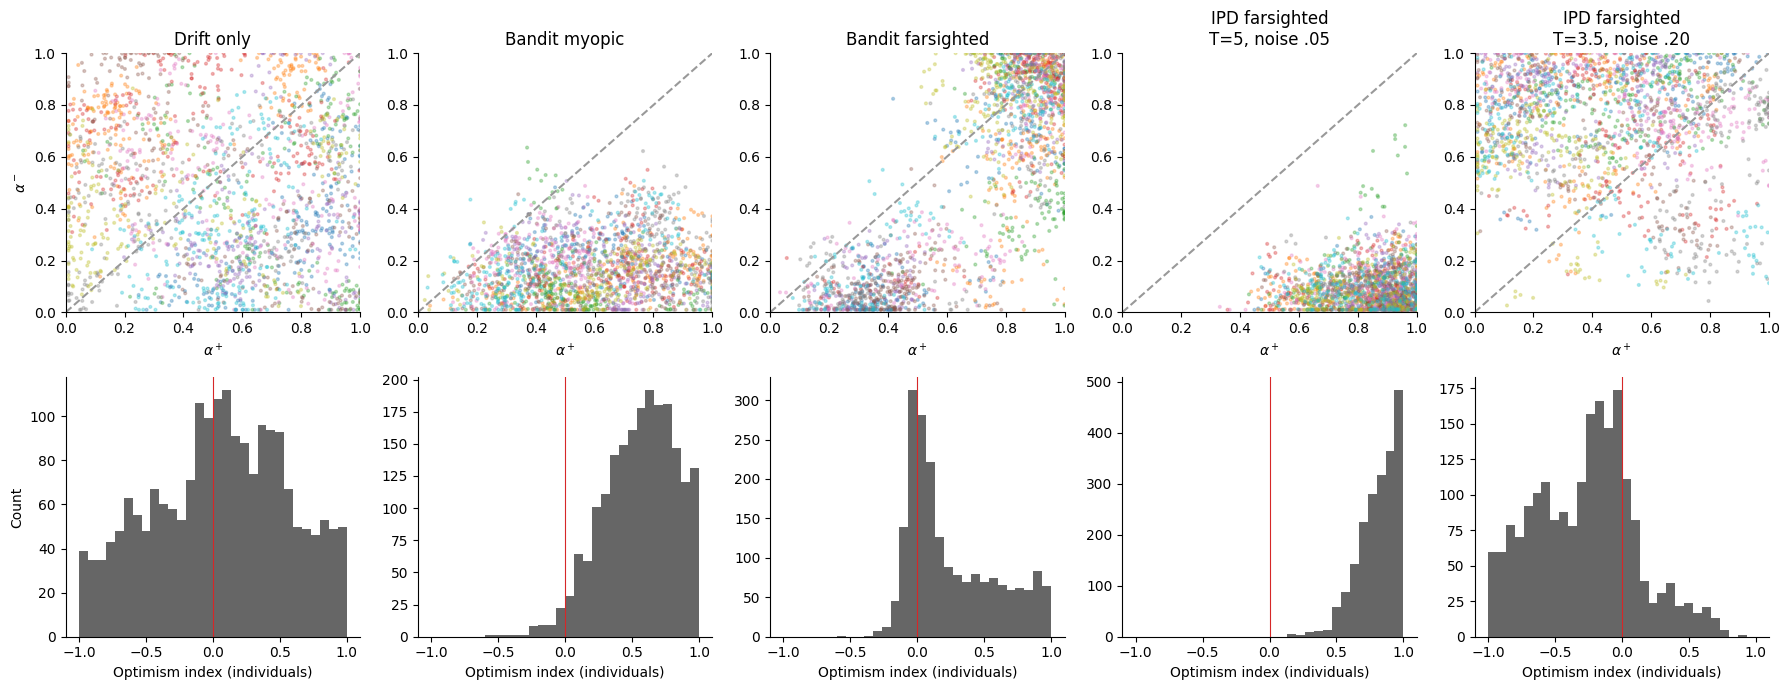

In [ ]:
DIST = [
    ("Drift only",                        random_lifetime,            {}),
    ("Bandit myopic",                     bandit_lifetime,            {}),
    ("Bandit farsighted",                 bandit_lifetime_farsighted, {}),
    ("IPD farsighted\nT=5, noise .05",   ipd_lifetime,               dict(noise=0.05)),
    ("IPD farsighted\nT=3.5, noise .20", ipd_lifetime,               dict(noise=0.20, temptation=3.5)),
]
fig, axes = plt.subplots(2, len(DIST), figsize=(18, 7))
for k, (label, fn, kw) in enumerate(DIST):
    runs = [evolve(fn, n_generations=N_GEN, seed=s, **kw) for s in range(N_SEEDS)]
    ap = np.concatenate([r["final_a_pos"] for r in runs]); an = np.concatenate([r["final_a_neg"] for r in runs])
    idx = (ap - an) / (ap + an)
    print(f"{label.replace(chr(10), ' '):<32} alpha+ = {ap.mean():.2f}, alpha- = {an.mean():.2f}, "
          f"index = {idx.mean():+.2f}; share optimistic = {(idx > 0).mean():.0%}")
    ax = axes[0, k]
    ax.scatter(ap, an, s=4, alpha=0.3, c=np.repeat(np.arange(N_SEEDS), len(runs[0]["final_a_pos"])), cmap="tab10")
    ax.plot([0, 1], [0, 1], ls="--", c="0.6")
    ax.set(xlim=(0, 1), ylim=(0, 1), title=label, xlabel=r"$\alpha^+$", ylabel=r"$\alpha^-$" if k == 0 else "")
    axes[1, k].hist(idx, bins=30, range=(-1, 1), color="0.4")
    axes[1, k].axvline(0, c="tab:red", lw=0.8)
    axes[1, k].set(xlabel="Optimism index (individuals)", ylabel="Count" if k == 0 else "")
for ax in axes.flat: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/03_distributions.png", dpi=150); plt.show()